# 1. Preparando a base

In [ ]:
# importa as bibliotecas e define o tema dos gráficos
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import (
    MinMaxScaler,
    PowerTransformer,
    RobustScaler,
    StandardScaler,
)

sns.set_theme(style="whitegrid", palette="colorblind")

In [2]:
# renomeia as colunas retirando espaços e símbolos
column_names = {
    "parking spaces": "parking_spaces",
    "hoa (R$)": "hoa",
    "rent amount (R$)": "rent_amount",
    "property tax (R$)": "property_tax",
    "total (R$)": "total",
}

In [ ]:
# carrega a base, remove duplicatas e identifica o tipo de imóvel
imoveis = (
    pd.read_csv("data/imoveis_sao_paulo.csv")
    .rename(columns=column_names)
    .drop_duplicates()
    .reset_index(drop=True)
    .assign( # adiciona novas colunas ou modifica colunas existentes no DF
        property_type=lambda df: np.where( # se floor é NULO/NaN assume o valor "casa", senão assume o valor "apartamento" 
            df["floor"].isna(),
            "casa",
            "apartamento",
        )
    )
)

In [4]:
missing = (
    imoveis[["hoa", "parking_spaces", "floor"]]
    .isna()
    .mean()
    .mul(100)
) # % de dados ausentes por coluna

scales = (
    imoveis[["rooms", "area", "rent_amount"]]
    .median()
) # mediana por coluna

limit = imoveis["rent_amount"].quantile(.99)
# tirar os outliers da coluna rent_amount

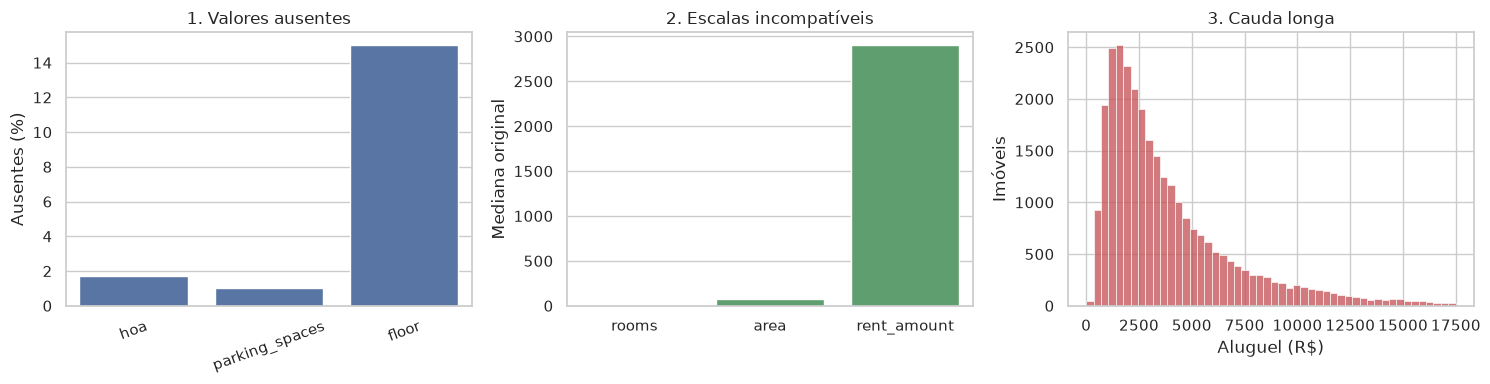

In [5]:
# graficos
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.barplot(
    x=missing.index,
    y=missing.values,
    ax=axes[0],
    color="#4C72B0",
)
axes[0].set(
    title="1. Valores ausentes",
    ylabel="Ausentes (%)",
    xlabel="",
)
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    x=scales.index,
    y=scales.values,
    ax=axes[1],
    color="#55A868",
)
axes[1].set(
    title="2. Escalas incompatíveis",
    ylabel="Mediana original",
    xlabel="",
)

sns.histplot(
    imoveis["rent_amount"],
    bins=50,
    binrange=(0, limit),
    ax=axes[2],
    color="#C44E52",
)
axes[2].set(
    title="3. Cauda longa",
    xlabel="Aluguel (R$)",
    ylabel="Imóveis",
)

plt.tight_layout()
plt.show()

# 2. Ausência estrutural

In [6]:
# casas não tem andar, apartamentos sim, proporção de imóveis sem andar por tipo de imóvel
(
    imoveis
    .groupby("property_type")
    .agg(
        imoveis=("property_type", "size"),
        proporcao_sem_andar=(
            "floor",
            lambda x: (
                x
                .isna()
                .mean()
            ),
        ),
    )
)

,imoveis,proporcao_sem_andar
property_type,,
apartamento,25024,0.0
casa,4415,1.0


# 3. Imputação

Imputar: substituir um valor ausente por uma estimativa calculada a partir das informações disponíveis. 

In [8]:
# simula a perda de dados de forma controlada
rng = np.random.default_rng(42) # seed

def erase_at_random(values, share):
    return values.mask(rng.random(len(values)) < share)

imoveis_true = (
    imoveis
    .dropna(subset=["hoa", "parking_spaces"])
    .reset_index(drop=True)
)

In [9]:
# apaga valores em três colunas de tipos diferentes
imoveis_missing = (
    imoveis_true
    .assign(
        rooms=lambda df: erase_at_random(df["rooms"], .10),
        rent_amount=lambda df: erase_at_random(df["rent_amount"], .15),
        furniture=lambda df: erase_at_random(df["furniture"], .08),
    )
)

In [10]:
# quantidade e proporção de valores apagados por coluna
(
    imoveis_missing[["rooms", "rent_amount", "furniture"]]
    .isna()
    .sum()
    .to_frame("ausentes")
    .assign(
        proporcao=lambda x: (
            x.ausentes / len(imoveis_missing)
        ).round(3)
    )
)

,ausentes,proporcao
rooms,2783,0.097
rent_amount,4308,0.150
furniture,2254,0.079


A média utiliza toda a magnitude dos dados e, por isso, responde fortemente a valores extremos. 
A mediana depende apenas da ordenação e é mais resistente a caudas longas.

In [11]:
# constantes para a imputação simples
rent_mean = (
    imoveis_missing.rent_amount
    .mean()
)

rent_median = (
    imoveis_missing.rent_amount
    .median()
)

A mediana por tier condiciona a estimativa ao padrão do imóvel. 
Cada lacuna recebe a mediana calculada entre os anúncios do mesmo grupo.

In [12]:
# imputação pela mediana de cada tier
rent_group = (
    imoveis_missing
    .groupby("tier")
    .rent_amount
    .transform(lambda x: x.fillna(x.median()))
    .fillna(rent_median)
)

In [ ]:
# versões do aluguel a comparar
rent_versions = {
    "Original": imoveis_true.rent_amount,
    "Com lacunas": imoveis_missing.rent_amount,
    "Média": imoveis_missing.rent_amount.fillna(rent_mean),
    "Mediana": imoveis_missing.rent_amount.fillna(rent_median),
    "Mediana por tier": rent_group,
}

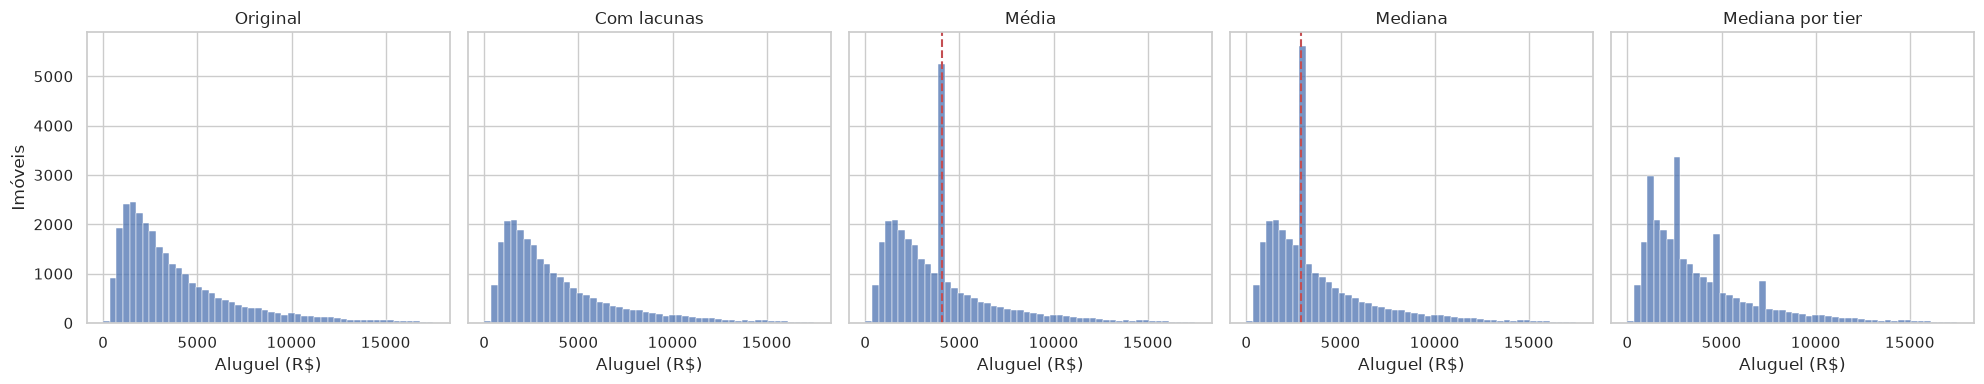

In [14]:
# histograma de cada versão do aluguel
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)

limit = imoveis_true.rent_amount.quantile(.99)

for ax, (label, values) in zip(axes, rent_versions.items()):
    sns.histplot(
        values.dropna(),
        bins=50,
        binrange=(0, limit),
        ax=ax,
        color="#4C72B0",
    )
    ax.set(
        title=label,
        xlabel="Aluguel (R$)",
        ylabel="Imóveis",
    )
    if label == "Média":
        ax.axvline(
            rent_mean,
            color="#C44E52",
            linestyle="--",
        )
    if label == "Mediana":
        ax.axvline(
            rent_median,
            color="#C44E52",
            linestyle="--",
        )

plt.tight_layout()
plt.show()

In [15]:
# posições apagadas e seus valores verdadeiros
rent_missing = imoveis_missing.rent_amount.isna()

truth = imoveis_true.loc[rent_missing, "rent_amount"]

In [16]:
(
    pd.Series(
        {
            "Média": (
                (truth - rent_mean)
                .abs()
                .mean()
            ),
            "Mediana": (
                (truth - rent_median)
                .abs()
                .mean()
            ),
            "Mediana por tier": (
                (truth - rent_group[rent_missing])
                .abs()
                .mean()
            ),
        },
        name="MAE (R$)",
    )
    .round(2)
    .to_frame()
)

,MAE (R$)
Média,2505.30
Mediana,2313.52
Mediana por tier,1820.84


In [17]:
# categoria mais frequente de furniture
furniture_mode = (
    imoveis_missing.furniture
    .mode()
    .iloc[0]
)

furniture_mode

'not furnished'

In [18]:
# contagem das categorias antes e depois da imputação
(
    pd.concat(
        {
            "Antes": imoveis_missing.furniture.value_counts(dropna=False),
            "Depois da moda": (
                imoveis_missing.furniture
                .fillna(furniture_mode)
                .value_counts()
            ),
        },
        axis=1,
    )
    .fillna(0)
)

,Antes,Depois da moda
furniture,,
not furnished,17265,19519.0
furnished,9122,9122.0
NaN,2254,0.0


In [ ]:
# média, mediana e moda de cada quarto
# MAE
(
    pd.Series(
        {
            "média": imoveis_missing.rooms.mean(),
            "mediana": imoveis_missing.rooms.median(),
            "moda": (
                imoveis_missing.rooms
                .mode()
                .iloc[0]
            ),
        },
        name="quartos",
    )
    .to_frame()
)

,quartos
média,2.262085
mediana,2.000000
moda,2.000000


# 4. Escalonamento

Escalonamento tem como objetivo colocar variáveis numéricas em escalas comparáveis.
É mudar a origem e a unidade de uma variável sem alterar sua forma

In [20]:
rent_frame = imoveis_true[["rent_amount"]]

scaled = {
    "Original": rent_frame.rent_amount.to_numpy(),

    # subtrai a média e divide pelo desvio padrão. Os dados passam a ter média = 0 e desvio padrão = 1.
    "StandardScaler": (
        StandardScaler()
        .fit_transform(rent_frame) # calcula os parâmetros e aplica a transformação nos dados.
        .ravel() # achata a matriz (de 2D para 1D) para facilitar a plotagem.
    ),
    
    # subtrai a mediana e divide pela amplitude interquartil (IQR = Q3 - Q1)
    # ideal quando existem outliers na base, pois não é distorcido por eles
    "RobustScaler": (
        RobustScaler()
        .fit_transform(rent_frame)
        .ravel()
    ),
    
    # reescalona todos os valores para ficarem estritamente dentro de um intervalo fixo
    # o menor valor da base vira 0 e o maior vira 1.
    "MinMaxScaler": (
        MinMaxScaler()
        .fit_transform(rent_frame)
        .ravel()
    ),
}

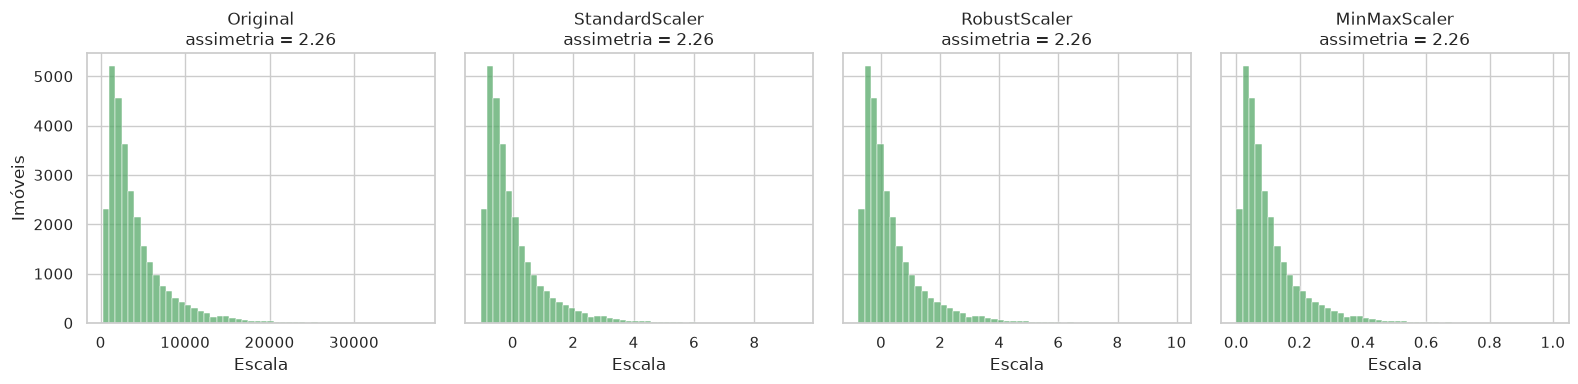

In [21]:
# histograma do aluguel em cada escala
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)

for ax, (label, values) in zip(axes, scaled.items()):
    sns.histplot(values, bins=50, ax=ax, color="#55A868")
    ax.set(
        title=f"{label}\nassimetria = {stats.skew(values):.2f}",
        xlabel="Escala",
        ylabel="Imóveis",
    )

plt.tight_layout()
plt.show()

In [ ]:
# ajustado com um aluguel fictício de R$ 500 mil
with_extreme = pd.concat(
    [rent_frame, pd.DataFrame({"rent_amount": [500_000.]})],
    ignore_index=True,
)

minmax_extreme = (
    MinMaxScaler()
    .fit_transform(with_extreme)
    .ravel()[:-1]
)

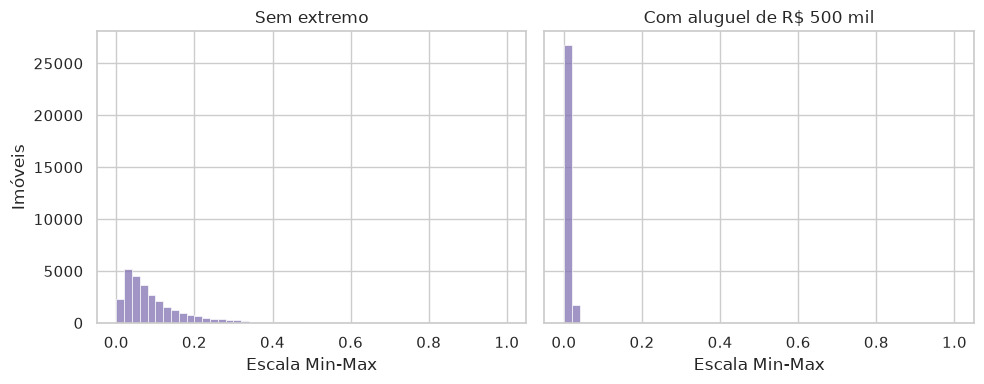

In [23]:
# grafico que mostra o efeito do min-max com e sem valores extremos
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

for ax, values, title in zip(
    axes,
    [scaled["MinMaxScaler"], minmax_extreme],
    ["Sem extremo", "Com aluguel de R$ 500 mil"],
):
    sns.histplot(
        values,
        bins=50,
        binrange=(0, 1),
        ax=ax,
        color="#8172B2",
    )
    ax.set(
        title=title,
        xlabel="Escala Min-Max",
        ylabel="Imóveis",
    )

plt.tight_layout()
plt.show()

# 5. Transformação

Nessa seção normalizar significa transformar a distribuição, aproximando ela a uma forma mais simétricca (normal)

In [ ]:
# aluguel original em log e em Box-Cox
rent = imoveis_true.rent_amount

boxcox_rent, boxcox_lambda = stats.boxcox(rent)

rent_transformed = {
    "Original": rent,
    "log": np.log(rent),
    f"Box-Cox (λ={boxcox_lambda:.2f})": boxcox_rent,
}

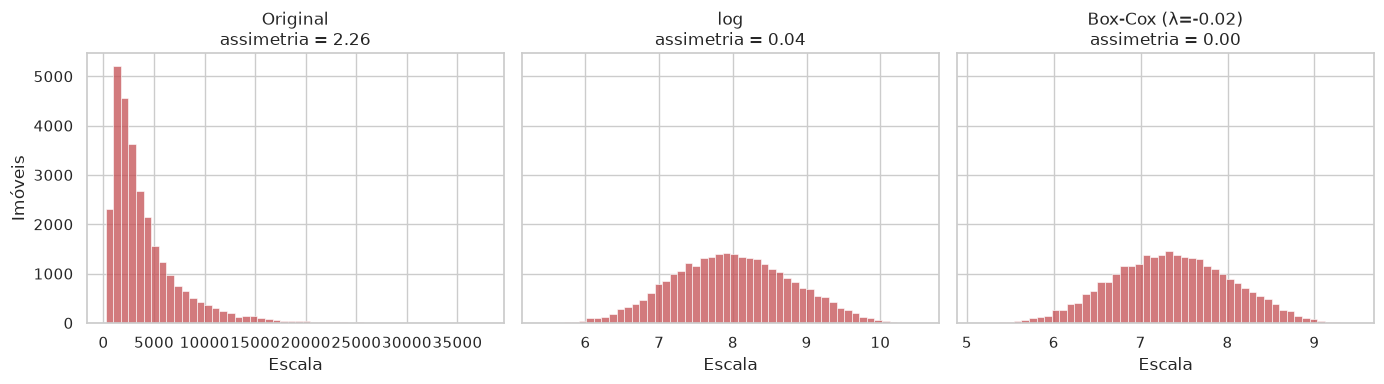

In [ ]:
# histogramas das transformações do aluguel
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

for ax, (label, values) in zip(axes, rent_transformed.items()):
    sns.histplot(values, bins=50, ax=ax, color="#C44E52")
    ax.set(
        title=f"{label}\nassimetria = {stats.skew(values):.2f}",
        xlabel="Escala",
        ylabel="Imóveis",
    )

plt.tight_layout()
plt.show()

In [26]:
# Distância original, em log1p e em Yeo-Johnson
transit = imoveis_true.transit_distance_min

pt = PowerTransformer(method="yeo-johnson", standardize=False)

transit_yj = (
    pt
    .fit_transform(imoveis_true[["transit_distance_min"]])
    .ravel()
)

transformed = {
    "Original": transit,
    "log1p": np.log1p(transit),
    f"Yeo-Johnson (λ={pt.lambdas_[0]:.2f})": transit_yj,
}

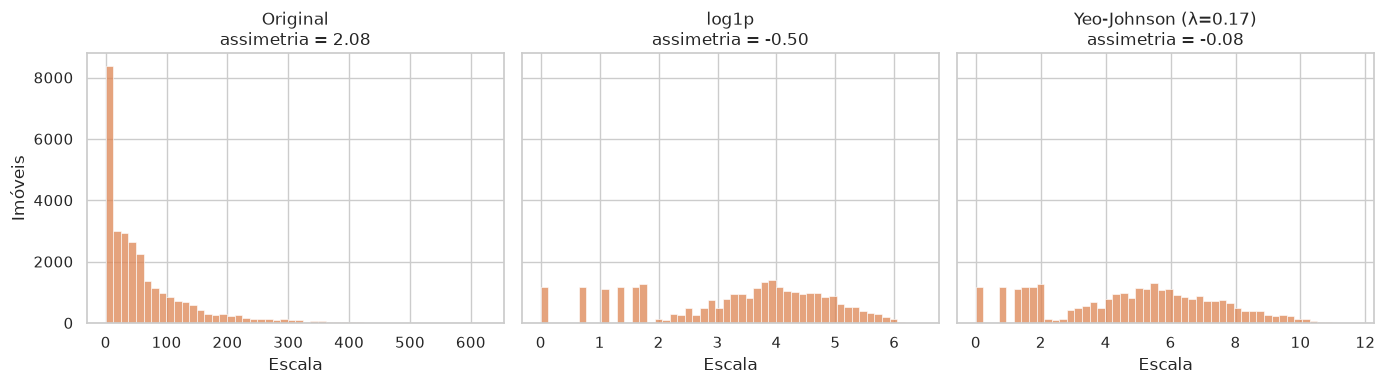

In [27]:
# Histogramas das transformações da distância
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

for ax, (label, values) in zip(axes, transformed.items()):
    sns.histplot(values, bins=50, ax=ax, color="#DD8452")
    ax.set(
        title=f"{label}\nassimetria = {stats.skew(values):.2f}",
        xlabel="Escala",
        ylabel="Imóveis",
    )

plt.tight_layout()
plt.show()

# 6. Aplicação e comparação final

In [28]:
# colunas indicadoras criadas antes da imputação
imoveis_processed = (
    imoveis
    .assign(
        hoa_missing=lambda x: x.hoa.isna(),
        parking_spaces_missing=lambda x: x.parking_spaces.isna(),
    )
)

In [29]:
# a partir da mediana de cada grupo, imputa hoa e vagas 
groups = ["property_type", "tier"]

imoveis_processed = (
    imoveis_processed
    .assign(
        hoa=lambda x: (
            x
            .groupby(groups)
            .hoa
            .transform(lambda s: s.fillna(s.median()))
            .fillna(imoveis.hoa.median())
        ),
        parking_spaces=lambda x: (
            x
            .groupby(groups)
            .parking_spaces
            .transform(lambda s: s.fillna(s.median()))
            .fillna(imoveis.parking_spaces.median())
        ),
    )
)

In [30]:
# conferir as lacunas restantes e valores estimados
(
    imoveis_processed
    .agg(
        {
            "hoa": lambda s: s.isna().sum(),
            "parking_spaces": lambda s: s.isna().sum(),
            "hoa_missing": "sum",
            "parking_spaces_missing": "sum",
        }
    )
)

hoa                         0
parking_spaces              0
hoa_missing               505
parking_spaces_missing    297
dtype: int64

In [31]:
# reduzindo as caudas, logo aplicar Log nas variáveis positivas e Yeo-Johnson na distância
imoveis_processed = (
    imoveis_processed
    .assign(
        area=lambda x: np.log(x.area),
        rent_amount=lambda x: np.log(x.rent_amount),
        property_tax=lambda x: np.log(x.property_tax),
        total=lambda x: np.log(x.total),
        transit_distance_min=lambda x: stats.yeojohnson(
            x.transit_distance_min
        )[0],
    )
)

In [ ]:
# variáveis comparadas e seus rótulos nos gráficos
columns = [
    "area",
    "rent_amount",
    "property_tax",
    "total",
    "transit_distance_min",
]

labels = ["Área", "Aluguel", "IPTU", "Total", "Distância"]

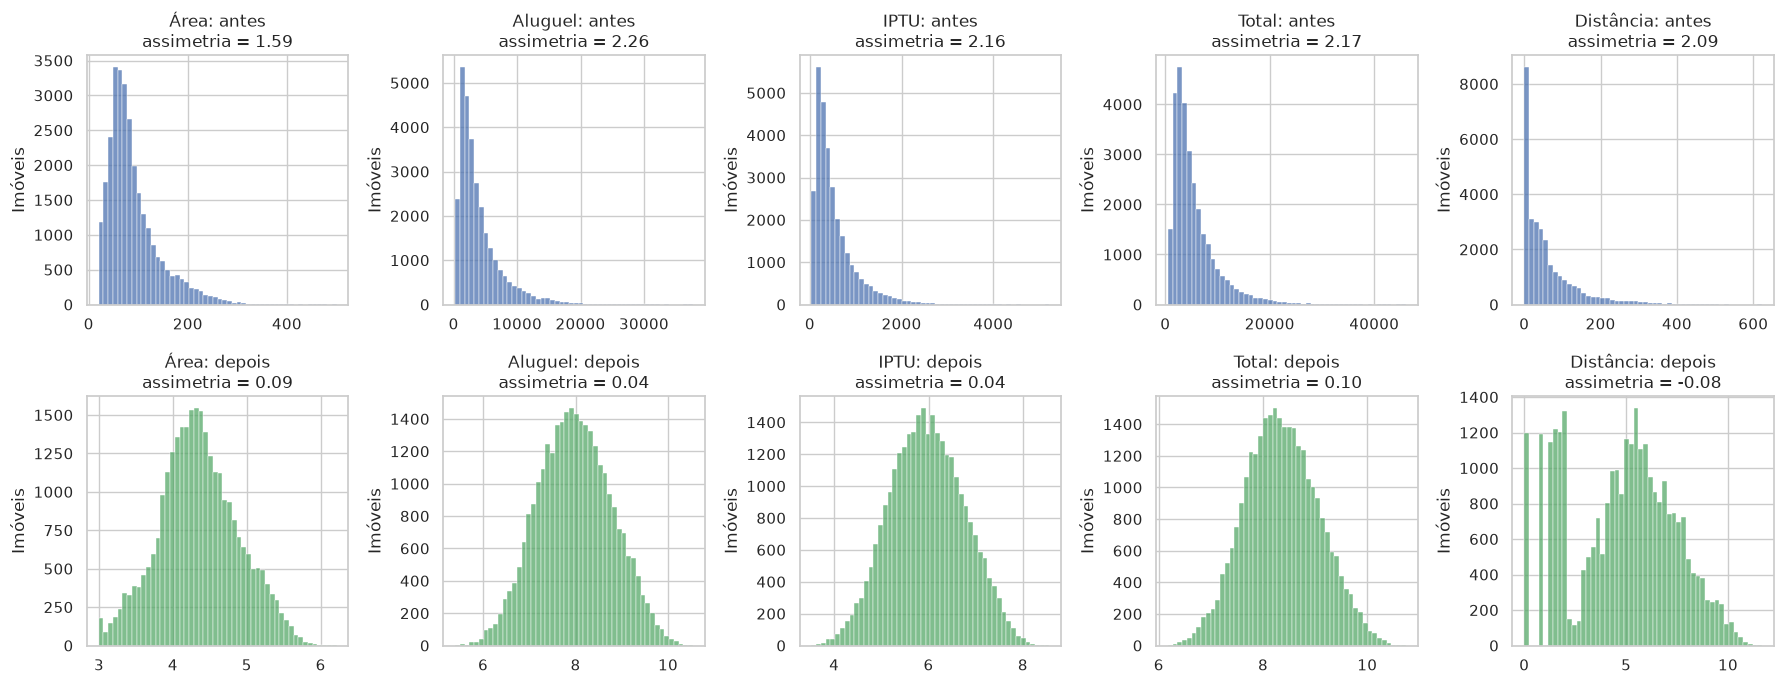

In [ ]:
# distribuições antes e depois
fig, axes = plt.subplots(2, 5, figsize=(18, 7))

for col, label, ax1, ax2 in zip(columns, labels, axes[0], axes[1]):
    before, after = imoveis[col], imoveis_processed[col]
    sns.histplot(before, bins=50, ax=ax1, color="#4C72B0")
    ax1.set(
        title=f"{label}: antes\nassimetria = {stats.skew(before):.2f}",
        xlabel="",
        ylabel="Imóveis",
    )
    sns.histplot(after, bins=50, ax=ax2, color="#55A868")
    ax2.set(
        title=f"{label}: depois\nassimetria = {stats.skew(after):.2f}",
        xlabel="",
        ylabel="Imóveis",
    )

plt.tight_layout()
plt.show()

# 7. Questões para casa

#### 1. Compare o MAE da média e da mediana para rooms e relacione o resultado à assimetria e ao caráter discreto da variável

In [ ]:
#  posições apagadas e pegar os valores verdadeiros
rooms_missing = imoveis_missing.rooms.isna()
truth_rooms = imoveis_true.loc[rooms_missing, "rooms"]

# estimativas
rooms_mean = imoveis_missing.rooms.mean()
rooms_median = imoveis_missing.rooms.median()

# calcular o MAE 
(
    pd.Series(
        {
            "Média": (
                (truth_rooms - rooms_mean)
                .abs()
                .mean()
            ),
            "Mediana": (
                (truth_rooms - rooms_median)
                .abs()
                .mean()
            )
        },
        name="MAE (Quartos)",
    )
    .round(2)
    .to_frame()
)

,MAE (Quartos)
Média,0.99
Mediana,0.93


#### 2. Impute o aluguel por tier e zona. Depois, use o bairro como grupo e discuta o efeito de grupos pequenos.

In [ ]:
# Imputando o aluguel pela mediana de cada tier
rent_mean = (
    imoveis_missing.rent_amount
    .mean()
)

rent_median = (
    imoveis_missing.rent_amount
    .median()
)

rent_group = (
    imoveis_missing
    .groupby("tier")
    .rent_amount
    .transform(lambda x: x.fillna(x.median()))
    .fillna(rent_median)
)

In [ ]:
# imputando o aluguel pela mediana de cada zona
rent_mean = (
    imoveis_missing.rent_amount
    .mean()
)

rent_median = (
    imoveis_missing.rent_amount
    .median()
)

rent_group = (
    imoveis_missing
    .groupby("zona")
    .rent_amount
    .transform(lambda x: x.fillna(x.median()))
    .fillna(rent_median)
)

#### 3. Entre apartamentos, compare log1p, Box-Cox e Yeo-Johnson para hoa. Qual produz menor assimetria? Qual você apresentaria a um gestor?